# Post-Harvest Crop Storage Loss Prediction Using an ANN

**Purpose:** Train a feedforward Multilayer Perceptron (MLP) regression model to estimate the percentage of net crop weight loss during storage from crop and storage-condition features.

> **Dataset notice:** The included `storage_data.csv` is a reproducible **synthetic demonstration dataset**, not field measurements. It is suitable for testing the code and demonstrating an ANN workflow, but it must not be used to claim real-world predictive accuracy. Replace or supplement it with properly collected measurements before drawing agricultural conclusions.

The notebook:
1. Loads and explores the CSV dataset.
2. Checks the target and predictor columns.
3. Splits data into training, validation and test sets.
4. Encodes categorical features and scales numeric features.
5. Trains an ANN regressor using TensorFlow/Keras.
6. Evaluates MAE, RMSE and R², and plots diagnostic charts.
7. Saves the trained model and preprocessing pipeline.
8. Provides additional prediction examples at the end.

## 1. Install and import libraries

Run the installation cell if your environment does not already contain the required packages. In Google Colab, upload the project folder or place the CSV at the expected path.

In [1]:
# Uncomment if needed (e.g. in Google Colab)
# !pip install -r ../requirements.txt

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths work when this notebook is run from notebooks/
DATA_PATH = "../dataset/storage_data.csv"
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load and inspect the CSV dataset

Each row represents one sample or storage observation. In a real study, document whether rows are independent samples or repeated observations from the same container. Repeated measurements from one container must not be randomly scattered across train and test sets.

In [2]:
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)
print("\\nMissing values:\\n", df.isna().sum())
print("\\nSummary:\\n")
display(df.describe(include="all").T)

,sample_id,crop_type,storage_duration_days,average_temperature_c,average_relative_humidity_pct,initial_moisture_content_pct,storage_method,pest_level,ventilation,initial_net_weight_kg,final_net_weight_kg,weight_loss_pct,data_origin
0,S0001,Wheat,141,25.09,77.93,14.97,Hermetic bag,High,Good,39.251,38.005,3.1760,synthetic_demo
1,S0002,Pulses,29,25.36,53.54,17.27,Metal silo,Medium,Moderate,24.954,24.554,1.6024,synthetic_demo
2,S0003,Wheat,103,16.47,76.38,14.32,Hermetic bag,Low,Poor,48.681,47.699,2.0180,synthetic_demo
3,S0004,Groundnuts,142,19.48,58.34,8.44,Warehouse,Low,Good,38.514,37.810,1.8294,synthetic_demo
4,S0005,Maize,63,23.52,58.48,9.89,Ordinary bag,Low,Good,15.211,14.914,1.9543,synthetic_demo


Shape: (720, 13)
\nMissing values:\n sample_id                          0
crop_type                          0
storage_duration_days              0
average_temperature_c              0
average_relative_humidity_pct      0
initial_moisture_content_pct       0
storage_method                     0
pest_level                       245
ventilation                        0
initial_net_weight_kg              0
final_net_weight_kg                0
weight_loss_pct                    0
data_origin                        0
dtype: int64
\nSummary:\n


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,720,720,S0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crop_type,720,6,Soybean,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
storage_duration_days,720.0,NaN,NaN,NaN,90.909722,49.996678,7.0,49.0,89.0,135.25,180.0
average_temperature_c,720.0,NaN,NaN,NaN,26.332556,6.69638,15.01,20.59,26.365,32.25,37.93
average_relative_humidity_pct,720.0,NaN,NaN,NaN,59.655972,14.534724,35.23,46.8825,58.99,72.4425,84.99
initial_moisture_content_pct,720.0,NaN,NaN,NaN,13.042917,2.896669,8.01,10.4975,13.08,15.49,17.99
storage_method,720,4,Metal silo,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pest_level,475,3,Low,253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ventilation,720,3,Good,259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
initial_net_weight_kg,720.0,NaN,NaN,NaN,27.037453,13.023548,5.175,15.87225,26.625,38.52725,49.974


## 3. Define target and input features

The target is weight-loss percentage:

\[
Loss(\\%) = 100 \\times \\frac{W_i-W_f}{W_i}
\]

where \(W_i\) is initial net crop weight and \(W_f\) is final net crop weight.

**Important:** Initial and final weights are used to calculate the target, so they are deliberately excluded from the predictor inputs. Including them would leak the answer into the model. Initial net weight can instead be entered in the app after prediction to calculate estimated remaining quantity.

In [3]:
TARGET = "weight_loss_pct"
NUMERIC_FEATURES = [
    "storage_duration_days",
    "average_temperature_c",
    "average_relative_humidity_pct",
    "initial_moisture_content_pct",
]
CATEGORICAL_FEATURES = [
    "crop_type",
    "storage_method",
    "pest_level",
    "ventilation",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Validate required columns
required = FEATURES + [TARGET]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()

print("Predictor count:", len(FEATURES))
print("Target range:", float(y.min()), "to", float(y.max()), "%")

Predictor count: 8
Target range: 0.05 to 5.6691 %


## 4. Split the data

This starter example uses a random split because the supplied demonstration CSV contains independent synthetic rows. For actual experimental data with repeated readings per container, use a group-based split by container/sample ID or split by experiment/batch to prevent data leakage.

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Train: (504, 8) Validation: (108, 8) Test: (108, 8)


## 5. Preprocess numeric and categorical features

Numeric inputs are median-imputed and standardized. Categorical inputs are imputed with the most frequent category and one-hot encoded. The fitted preprocessor is saved and reused at prediction time; never fit a new scaler on user input or on the test set.

In [5]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])

X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")
X_test_p = preprocessor.transform(X_test).astype("float32")

print("Processed input shape:", X_train_p.shape)

Processed input shape: (504, 20)


## 6. Build the ANN (MLP) regression model

The network has an input layer matching the transformed feature count, two hidden dense layers using ReLU activation, and one linear output neuron. A linear output is appropriate for regression. Adam updates weights using gradients calculated by backpropagation; mean squared error is the training loss.

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_p.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="linear"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the ANN

Early stopping monitors validation loss and restores the best-performing weights. This helps reduce overfitting. The epoch count is a maximum, not a guarantee that every epoch will run.

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
)

history = model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 3.8649 - mae: 1.6624 - val_loss: 2.7006 - val_mae: 1.3205
Epoch 2/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.7494 - mae: 1.0498 - val_loss: 1.4064 - val_mae: 0.9534
Epoch 3/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0250 - mae: 0.8235 - val_loss: 0.9803 - val_mae: 0.7942
Epoch 4/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6795 - mae: 0.6728 - val_loss: 0.7168 - val_mae: 0.6682
Epoch 5/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4754 - mae: 0.5589 - val_loss: 0.5559 - val_mae: 0.5809
Epoch 6/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3598 - mae: 0.4839 - val_loss: 0.4545 - val_mae: 0.5239
Epoch 7/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2937 - mae: 0.4373 - val_loss: 0.3887 - val_mae: 0.4891
Epoch 8/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2557 - mae: 0.4095 - val_loss: 0.3464 - val_mae: 0.4644
Epoch 9/150
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.23

## 8. Visualize training and validation loss

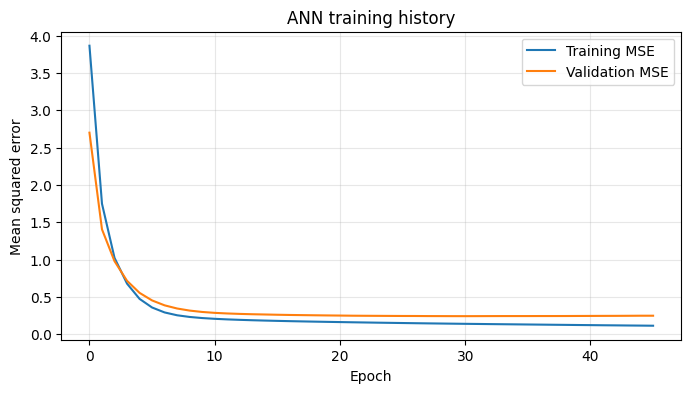

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("ANN training history")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 9. Evaluate on the held-out test set

MAE and RMSE are reported in percentage points of weight loss. R² describes the proportion of target variance explained on this test split; it can be negative if the model performs worse than predicting the test-set mean. These metrics on synthetic data only verify that the code executes.

In [9]:
y_pred = model.predict(X_test_p, verbose=0).ravel()
mae = mean_absolute_error(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = r2_score(y_test, y_pred)

print(f"Test MAE : {mae:.4f} percentage points")
print(f"Test RMSE: {rmse:.4f} percentage points")
print(f"Test R²  : {r2:.4f}")

Test MAE : 0.3843 percentage points
Test RMSE: 0.4866 percentage points
Test R²  : 0.7865


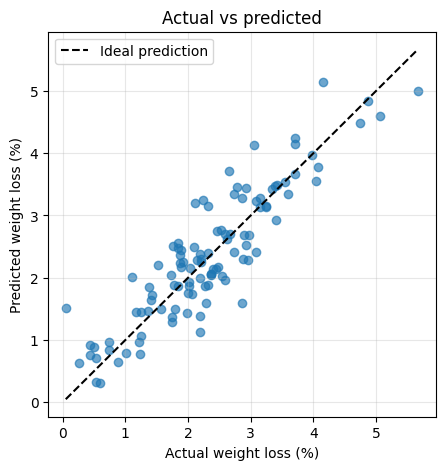

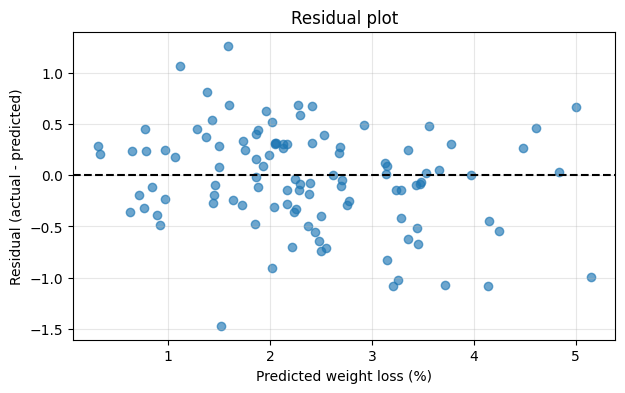

In [10]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.65)
lims = [min(float(y_test.min()), float(y_pred.min())),
        max(float(y_test.max()), float(y_pred.max()))]
plt.plot(lims, lims, "k--", label="Ideal prediction")
plt.xlabel("Actual weight loss (%)")
plt.ylabel("Predicted weight loss (%)")
plt.title("Actual vs predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, alpha=0.65)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted weight loss (%)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot")
plt.grid(True, alpha=0.3)
plt.show()

## 10. Save model, preprocessor and feature metadata

Keep the model and preprocessing pipeline together. The app must load the same fitted preprocessor used during training so that feature order, scaling and one-hot categories remain consistent.

In [11]:
model.save(os.path.join(MODEL_DIR, "storage_ann.keras"))
joblib.dump(preprocessor, os.path.join(MODEL_DIR, "preprocessor.pkl"))

metadata = {
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target": TARGET,
    "dataset_notice": "The bundled CSV is synthetic demonstration data."
}
with open(os.path.join(MODEL_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model and preprocessing files in:", MODEL_DIR)

Saved model and preprocessing files in: ../models


# 11. Additional prediction code snippets

The following examples show how to request predictions with different specifications. Run the training and save cells first. Inputs must use the same feature names and categories as the training data.

### Snippet A — reusable prediction function for one storage case

In [12]:
def predict_storage_loss(
    crop_type, storage_duration_days, average_temperature_c,
    average_relative_humidity_pct, initial_moisture_content_pct,
    storage_method, pest_level, ventilation, initial_weight_kg=None
):
    case = pd.DataFrame([{
        "crop_type": crop_type,
        "storage_duration_days": storage_duration_days,
        "average_temperature_c": average_temperature_c,
        "average_relative_humidity_pct": average_relative_humidity_pct,
        "initial_moisture_content_pct": initial_moisture_content_pct,
        "storage_method": storage_method,
        "pest_level": pest_level,
        "ventilation": ventilation,
    }])[FEATURES]

    case_p = preprocessor.transform(case).astype("float32")
    predicted_loss = float(model.predict(case_p, verbose=0)[0, 0])
    # Clamp only for display to physically plausible percentage bounds.
    predicted_loss = float(np.clip(predicted_loss, 0, 100))

    result = {"predicted_weight_loss_pct": predicted_loss}
    if initial_weight_kg is not None:
        result["estimated_remaining_weight_kg"] = initial_weight_kg * (1 - predicted_loss / 100)
    return result

# Example: change the values to test other storage conditions.
predict_storage_loss(
    crop_type="Wheat",
    storage_duration_days=60,
    average_temperature_c=27,
    average_relative_humidity_pct=65,
    initial_moisture_content_pct=12.5,
    storage_method="Ordinary bag",
    pest_level="Low",
    ventilation="Moderate",
    initial_weight_kg=100
)

{'predicted_weight_loss_pct': 1.8878573179244995,
 'estimated_remaining_weight_kg': 98.1121426820755}

### Snippet B — compare several crops under the same storage conditions

In [13]:
crop_comparison = []
for crop in ["Wheat", "Rice", "Maize", "Pulses", "Groundnuts", "Soybean"]:
    pred = predict_storage_loss(
        crop_type=crop,
        storage_duration_days=45,
        average_temperature_c=28,
        average_relative_humidity_pct=68,
        initial_moisture_content_pct=13,
        storage_method="Warehouse",
        pest_level="Low",
        ventilation="Moderate",
        initial_weight_kg=100
    )
    crop_comparison.append({"crop_type": crop, **pred})

display(pd.DataFrame(crop_comparison).sort_values("predicted_weight_loss_pct"))

,crop_type,predicted_weight_loss_pct,estimated_remaining_weight_kg
0,Wheat,1.107716,98.892284
1,Rice,1.445972,98.554028
3,Pulses,1.512314,98.487686
5,Soybean,1.521379,98.478621
4,Groundnuts,1.729524,98.270476
2,Maize,1.986929,98.013071


### Snippet C — compare storage methods for a selected crop

In [14]:
method_comparison = []
for method in ["Hermetic bag", "Ordinary bag", "Warehouse", "Metal silo"]:
    pred = predict_storage_loss(
        crop_type="Maize",
        storage_duration_days=90,
        average_temperature_c=30,
        average_relative_humidity_pct=72,
        initial_moisture_content_pct=14,
        storage_method=method,
        pest_level="Medium",
        ventilation="Moderate",
        initial_weight_kg=250
    )
    method_comparison.append({"storage_method": method, **pred})

display(pd.DataFrame(method_comparison).sort_values("predicted_weight_loss_pct"))

,storage_method,predicted_weight_loss_pct,estimated_remaining_weight_kg
0,Hermetic bag,2.816763,242.958092
3,Metal silo,3.107496,242.231261
2,Warehouse,3.483446,241.291384
1,Ordinary bag,3.828360,240.429101


### Snippet D — batch predictions from a user-provided CSV

In [15]:
# Prepare a CSV named new_storage_cases.csv with the 8 feature columns.
# Optional initial_net_weight_kg column is used only to calculate remaining mass.
# batch = pd.read_csv("new_storage_cases.csv")
#
# batch_features = batch[FEATURES]
# batch_processed = preprocessor.transform(batch_features).astype("float32")
# batch["predicted_weight_loss_pct"] = model.predict(batch_processed, verbose=0).ravel()
# if "initial_net_weight_kg" in batch.columns:
#     batch["estimated_remaining_weight_kg"] = (
#         batch["initial_net_weight_kg"] *
#         (1 - batch["predicted_weight_loss_pct"].clip(0, 100) / 100)
#     )
# batch.to_csv("storage_predictions.csv", index=False)
# display(batch.head())

### Snippet E — what-if analysis across temperature and humidity

In [16]:
what_if = []
for temp in [20, 25, 30, 35]:
    for humidity in [45, 60, 75, 85]:
        pred = predict_storage_loss(
            crop_type="Rice",
            storage_duration_days=60,
            average_temperature_c=temp,
            average_relative_humidity_pct=humidity,
            initial_moisture_content_pct=13,
            storage_method="Ordinary bag",
            pest_level="Low",
            ventilation="Moderate"
        )
        what_if.append({
            "temperature_c": temp,
            "relative_humidity_pct": humidity,
            **pred
        })

what_if_df = pd.DataFrame(what_if)
display(what_if_df)
pivot = what_if_df.pivot(
    index="temperature_c",
    columns="relative_humidity_pct",
    values="predicted_weight_loss_pct"
)
display(pivot.style.format("{:.2f}"))

,temperature_c,relative_humidity_pct,predicted_weight_loss_pct
0,20,45,1.519905
1,20,60,1.642793
2,20,75,2.115509
3,20,85,2.414760
4,25,45,1.551437
5,25,60,1.661832
6,25,75,2.086263
7,25,85,2.434120
8,30,45,1.559848
9,30,60,1.742398


relative_humidity_pct,45,60,75,85
temperature_c,,,,
20,1.52,1.64,2.12,2.41
25,1.55,1.66,2.09,2.43
30,1.56,1.74,2.26,2.70
35,1.82,2.06,2.50,2.94


## 12. How the model works — explanation for the project report

1. **Input:** The user supplies crop type, storage duration, average storage temperature, average relative humidity, initial moisture content, storage method, pest level and ventilation.
2. **Preprocessing:** Numeric values are standardized using statistics learned from the training set. Categorical values are converted into one-hot indicator columns.
3. **Forward propagation:** The processed feature vector passes through two dense hidden layers (32 and 16 neurons). ReLU activation allows the network to learn nonlinear relationships. The output neuron produces one continuous value: predicted weight-loss percentage.
4. **Loss calculation:** During training, the predicted percentage is compared with the measured target using mean squared error (MSE).
5. **Backpropagation:** TensorFlow calculates gradients of the loss with respect to the network weights. Adam uses those gradients to update the weights and reduce prediction error.
6. **Evaluation:** Predictions on data not used for fitting are compared with actual targets using MAE, RMSE and R².
7. **Deployment:** The saved ANN and the exact fitted preprocessing pipeline are loaded by the Streamlit app. The app predicts loss; if the user supplies starting net weight, estimated remaining mass is calculated as `initial_weight × (1 − predicted_loss/100)`.

**Scientific limitations:** Observed mass change can include moisture evaporation, not only biological deterioration or pest damage. Measure final moisture content and define the target consistently. If the goal is dry-matter loss, calculate a moisture-corrected target using moisture fractions (e.g. 0.12, not 12): `100 × [Wi(1−Mi) − Wf(1−Mf)] / [Wi(1−Mi)]`. Collect real replicated measurements, summarize temperature/humidity over the full storage interval, and split repeated observations by physical sample/container to avoid leakage. Do not treat synthetic-data performance as evidence of real-world accuracy.